# De la señal a la pseudodistancia: qué mide un receptor GNSS

Este cuaderno acompaña la unidad de *sistemas de posicionamiento satelital (GNSS)*. Parte de un día de datos reales —la estación permanente **BOGT** (Bogotá, red IGS, operada por NASA/JPL), 15 de septiembre de 2026— y llega, término a término, hasta la **ecuación de la pseudodistancia**, el punto de partida de todo el posicionamiento por satélite.

Cada sección sigue el mismo patrón: una definición breve, el cálculo con los datos, y una figura. Los datos son los dos archivos RINEX del día, guardados en `data/`; la **sección 0** los lee y arma la tabla con la que trabaja el resto del cuaderno. Las cifras que aparecen en el texto son las de BOGT el 15 de septiembre a las 12:00:00 con el satélite G15; con otra estación, otra fecha u otro satélite los cálculos se repiten igual y los números cambian.

**La tabla `D`** tiene una fila por época y satélite GPS:

| columna | qué es | unidad |
|---|---|---|
| `t` | instante de la medida (época), en tiempo GPS | fecha y hora |
| `sv` | satélite (G + número PRN) | — |
| `P1`, `P2` | pseudodistancia medida con el código en las portadoras L1 y L2 | m |
| `L1` | fase de la portadora L1 (conteo de ciclos) | ciclos |
| `S1` | intensidad de la señal recibida en L1 | dB·Hz |
| `xs`, `ys`, `zs` | posición del satélite en el instante en que emitió la señal, calculada con sus efemérides | m (geocéntricas) |
| `dts` | corrección del reloj del satélite, calculada con los coeficientes que él mismo transmite | s |
| `el`, `az` | elevación y acimut del satélite vistos desde la estación | grados |

> **Estación GNSS permanente** — receptor con antena fija que registra sin interrupción las señales de los satélites de navegación y publica sus datos. BOGT pertenece al **IGS** (*International GNSS Service*), la red mundial de estaciones de este tipo que existe desde 1994.

### Datos de otras estaciones

Los archivos del IGS se descargan sin registro del centro de datos de BKG (Alemania). La ruta es `https://igs.bkg.bund.de/root_ftp/IGS/obs/AAAA/DDD/`, con el año y el **día del año** (el 15 de septiembre de 2026 es el día 258), y el nombre de cada archivo se arma así:

`BOGT00COL_R_20262580000_01D_30S_MO.crx.gz` = estación `BOGT`, monumento y receptor `00`, país `COL` · `R` datos del receptor · `2026258` año y día · `0000` hora de inicio · `01D` un día · `30S` una época cada 30 s · `MO` observaciones (`MN` navegación) · `.crx.gz` comprimido (Hatanaka + gzip).

Enlaces comprobados el 23-oct-2026 para el **15 de septiembre de 2026** (para otro día se cambian `2026/258` y `2026258`):

| estación | lugar | observación | navegación | ficha IGS |
|---|---|---|---|---|
| `BOGT00COL` | Bogotá, Colombia | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BOGT00COL_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BOGT00COL_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BOGT00COL) |
| `GLPS00ECU` | Puerto Ayora, Galápagos, Ecuador | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/GLPS00ECU_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/GLPS00ECU_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/GLPS00ECU) |
| `AREQ00PER` | Arequipa, Perú | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/AREQ00PER_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/AREQ00PER_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/AREQ00PER) |
| `SANT00CHL` | Santiago, Chile | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/SANT00CHL_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/SANT00CHL_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/SANT00CHL) |
| `KOUR00GUF` | Kourou, Guayana Francesa | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/KOUR00GUF_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/KOUR00GUF_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/KOUR00GUF) |
| `CHPI00BRA` | Cachoeira Paulista, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CHPI00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CHPI00BRA_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/CHPI00BRA) |
| `CRO100VIR` | Saint Croix, Islas Vírgenes (EE. UU.) | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CRO100VIR_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CRO100VIR_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/CRO100VIR) |
| `LMMF00MTQ` | Le Lamentin, Martinica | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LMMF00MTQ_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LMMF00MTQ_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/LMMF00MTQ) |
| `ALGO00CAN` | Algonquin Park, Canadá | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ALGO00CAN_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ALGO00CAN_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/ALGO00CAN) |
| `WTZR00DEU` | Wettzell, Alemania | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/WTZR00DEU_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/WTZR00DEU_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/WTZR00DEU) |

Estas estaciones publican la observación pero no su propio archivo de navegación; se usa el archivo de navegación combinado de toda la red, que el cuaderno toma solo si falta el de la estación:

| estación | lugar | observación | navegación | ficha IGS |
|---|---|---|---|---|
| `BRAZ00BRA` | Brasilia, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BRAZ00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BRAZ00BRA) |
| `UNSA00ARG` | Salta, Argentina | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/UNSA00ARG_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/UNSA00ARG) |
| `LPGS00ARG` | La Plata, Argentina | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LPGS00ARG_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/LPGS00ARG) |
| `INEG00MEX` | Aguascalientes, México | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/INEG00MEX_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/INEG00MEX) |
| `UFPR00BRA` | Curitiba, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/UFPR00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/UFPR00BRA) |
| `BELE00BRA` | Belém, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BELE00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BELE00BRA) |

Para buscar más:

- Mapa de estaciones del IGS, con la ficha de cada una (receptor, antena, coordenadas, fotos): https://network.igs.org/
- Buscador de archivos de BKG: https://igs.bkg.bund.de/searchRINEX
- Listado completo de un día: https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ y la navegación combinada en https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/
- Estaciones de la Red Geodésica Nacional de Colombia (IGAC), en Colombia en Mapas: https://www.colombiaenmapas.gov.co/ (pueden venir en RINEX 2; este cuaderno lee RINEX 3).
- Archivo CDDIS de la NASA (mismos datos, requiere cuenta gratuita de Earthdata): https://cddis.nasa.gov/archive/gnss/data/daily/

Para procesar otra estación: cambiar `ESTACION`, `FECHA`, `HORA`, `SAT` y `HUSO` en la primera celda de la sección 0 y poner `DESCARGAR = True` (o dejar los dos archivos en `data/`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299_792_458.0

## 0. Del archivo RINEX a una tabla

> **RINEX** (*Receiver Independent Exchange Format*) — formato de texto estándar en el que cualquier receptor publica sus medidas. Hay dos archivos por día y estación: el de **observación** (`…_MO`), con una línea por época y satélite, y el de **navegación** (`…_MN`), con las efemérides y la corrección del reloj que transmitió cada satélite.

Esta sección lee los dos archivos de la estación y arma una tabla `D` con una fila por época y satélite GPS. Para usar otra estación u otro día basta cambiar `ESTACION` y `FECHA` en la celda siguiente, y si hace falta la época (`HORA`), el satélite que se sigue (`SAT`) y el huso horario (`HUSO`) (con `DESCARGAR = True` el cuaderno baja los archivos del centro de datos del IGS en BKG si no están en `data/`). Requiere el paquete `hatanaka` (`pip install hatanaka`), que descomprime el formato comprimido de los archivos de observación (`.crx`).

In [2]:
# ── qué estación y qué día se procesan ──
ESTACION = "BOGT00COL"      # nombre IGS de 9 caracteres: 4 letras de la estación, monumento y receptor (00) y país (COL)
FECHA = "2026-09-15"        # día de los archivos (UTC)
HORA = "12:00:00"           # la época que se estudia en detalle (tiempo GPS)
SAT = "G15"                 # el satélite que se sigue durante su pase (debe estar visible a esa HORA)
HUSO = -5                   # hora local = UTC + HUSO (Colombia: −5)
DESCARGAR = False           # True: baja de BKG los archivos que no estén en data/

import gzip, urllib.request
from pathlib import Path
import hatanaka

dia = pd.Timestamp(FECHA)
ANIO, DDD = dia.year, f"{dia.dayofyear:03d}"            # el día del año: 15-sep-2026 es el 258
BKG = "https://igs.bkg.bund.de/root_ftp/IGS"
f_obs = f"{ESTACION}_R_{ANIO}{DDD}0000_01D_30S_MO.crx.gz"     # observaciones, una época cada 30 s
f_nav = f"{ESTACION}_R_{ANIO}{DDD}0000_01D_MN.rnx.gz"         # navegación grabada por la propia estación
f_brdc = f"BRDC00WRD_S_{ANIO}{DDD}0000_01D_MN.rnx.gz"         # navegación combinada de toda la red (si la estación no publica la suya)
DATA = Path("data")

def conseguir(nombre, url):
    """Devuelve la ruta local del archivo; si no está y DESCARGAR es True, lo baja. None si no existe en ninguna parte."""
    ruta = DATA / nombre
    if not ruta.exists() and DESCARGAR:
        try:
            urllib.request.urlretrieve(url, ruta)
            print("descargado:", nombre)
        except Exception as error:
            print("no disponible:", url, "|", error)
            return None
    return ruta if ruta.exists() else None

ruta_obs = conseguir(f_obs, f"{BKG}/obs/{ANIO}/{DDD}/{f_obs}")
ruta_nav = conseguir(f_nav, f"{BKG}/obs/{ANIO}/{DDD}/{f_nav}") or conseguir(f_brdc, f"{BKG}/BRDC/{ANIO}/{DDD}/{f_brdc}")
assert ruta_obs is not None and ruta_nav is not None, "faltan archivos: póngalos en data/ o use DESCARGAR = True"

# .crx.gz -> .rnx (Hatanaka + gzip) y .rnx.gz -> .rnx; si ya estaban descomprimidos no se repite
rnx_obs = hatanaka.decompress_on_disk(ruta_obs)
rnx_nav = hatanaka.decompress_on_disk(ruta_nav)
print("observación:", rnx_obs.name, "\nnavegación: ", rnx_nav.name)

observación: BOGT00COL_R_20262580000_01D_30S_MO.rnx 
navegación:  BOGT00COL_R_20262580000_01D_MN.rnx


In [3]:
def leer_obs_gps(ruta):
    """Lee un RINEX 3 de observación. Devuelve el encabezado (dict) y una tabla con una fila por época y satélite GPS."""
    lineas = open(ruta, encoding="latin-1").read().splitlines()
    enc, tipos, i = {}, {}, 0
    while True:                                               # encabezado: la etiqueta está en las columnas 61-80
        l, etiqueta = lineas[i], lineas[i][60:].strip()
        if etiqueta == "END OF HEADER":
            i += 1
            break
        if etiqueta == "SYS / # / OBS TYPES":
            if l[0] != " ":
                sistema = l[0]
                tipos[sistema] = l[7:60].split()
            else:                                             # línea de continuación (más de 13 tipos)
                tipos[sistema] += l[7:60].split()
        elif etiqueta == "APPROX POSITION XYZ":
            enc["xyz"] = [float(v) for v in l[:60].split()]
        elif etiqueta == "MARKER NAME":
            enc["estacion"] = l[:60].strip()
        elif etiqueta == "REC # / TYPE / VERS":
            enc["receptor"] = l[20:40].strip()
        elif etiqueta == "ANT # / TYPE":
            enc["antena"] = l[20:40].strip()
        elif etiqueta == "INTERVAL":
            enc["intervalo_s"] = float(l[:60])
        i += 1
    tg = tipos["G"]                                           # los tipos de observación de GPS, en su orden
    filas = []
    while i < len(lineas):
        l = lineas[i]
        if l.startswith(">"):                                 # línea de época: > aaaa mm dd hh mm ss.sssssss bandera n
            t = pd.Timestamp(int(l[2:6]), int(l[7:9]), int(l[10:12]), int(l[13:15]), int(l[16:18])) + pd.Timedelta(seconds=float(l[19:29]))
            n = int(l[32:35])
            for ll in lineas[i + 1:i + 1 + n]:
                if ll[0] == "G":                              # solo GPS; cada valor ocupa 16 columnas (14 del número + 2 banderas)
                    valores = [ll[3 + 16 * j:3 + 16 * j + 14].strip() for j in range(len(tg))]
                    filas.append([t, ll[:3]] + [float(v) if v else np.nan for v in valores])
            i += 1 + n
        else:
            i += 1
    enc["tipos_gps"] = tg
    return enc, pd.DataFrame(filas, columns=["t", "sv"] + tg)

enc, obs = leer_obs_gps(rnx_obs)
rx = np.array(enc["xyz"])          # posición de la estación del encabezado (APPROX POSITION XYZ): aproximada, al metro o mejor

# el código en L2 varía según el receptor: se usa el primero que tenga datos
codigo_L2 = next((c for c in ["C2W", "C2L", "C2X", "C2S", "C2P", "C2D"] if c in obs and obs[c].notna().any()), None)
obs["P2"] = obs[codigo_L2] if codigo_L2 else np.nan
for col in ["L1C", "S1C"]:                 # no todos los receptores registran la fase o la intensidad de L1C
    if col not in obs:
        obs[col] = np.nan
print(f"{enc['estacion']} · receptor {enc['receptor']} · antena {enc['antena']} · intervalo {enc['intervalo_s']:.0f} s")
print("tipos de observación GPS:", " ".join(enc["tipos_gps"]))
print("código usado en L2:", codigo_L2, "| filas GPS:", len(obs), "| épocas:", obs.t.nunique())

BOGT · receptor JAVAD TRE_3 DELTA · antena JAVRINGANT_DM   NONE · intervalo 30 s
tipos de observación GPS: C1C L1C S1C C1W L1W S1W C2X L2X S2X C2W L2W S2W C5X L5X S5X C1X L1X S1X
código usado en L2: C2W | filas GPS: 27358 | épocas: 2880


In [4]:
def leer_nav_gps(ruta):
    """Lee un RINEX 3 de navegación y devuelve las efemérides GPS: una fila por mensaje, con el instante de referencia del reloj (toc)."""
    lineas = open(ruta, encoding="latin-1").read().splitlines()
    i = next(k for k, l in enumerate(lineas) if "END OF HEADER" in l) + 1
    num = lambda s: float(s.replace("D", "E")) if s.strip() else np.nan        # los números vienen en notación Fortran (1.2D-03)
    campos = ["IODE", "Crs", "DeltaN", "M0", "Cuc", "e", "Cus", "sqrtA", "Toe", "Cic", "Omega0", "Cis",
              "i0", "Crc", "omega", "OmegaDot", "IDOT", "L2codes", "semana", "L2P", "precision", "salud", "TGD", "IODC"]
    lineas_por_sistema = {"G": 8, "E": 8, "C": 8, "J": 8, "I": 8, "R": 4, "S": 4}   # cada mensaje ocupa 8 líneas (GLONASS y SBAS, 4)
    filas = []
    while i < len(lineas):
        l = lineas[i]
        n = lineas_por_sistema.get(l[0], 1)
        if l[0] == "G":
            toc = pd.Timestamp(int(l[4:8]), int(l[9:11]), int(l[12:14]), int(l[15:17]), int(l[18:20]), int(l[21:23]))
            reloj = [num(l[23 + 19 * k:42 + 19 * k]) for k in range(3)]                  # af0 (s), af1 (s/s), af2 (s/s²)
            resto = [num(ll[4 + 19 * k:23 + 19 * k]) for ll in lineas[i + 1:i + 7] for k in range(4)]
            filas.append([l[:3], toc] + reloj + resto)
        i += n
    nav = pd.DataFrame(filas, columns=["sv", "toc", "af0", "af1", "af2"] + campos)
    return nav[nav.salud == 0].drop_duplicates(["sv", "toc"])        # solo mensajes de satélites sanos, sin repetidos

nav = leer_nav_gps(rnx_nav)
print(f"{len(nav)} mensajes de efemérides de {nav.sv.nunique()} satélites GPS")
nav.head(3)

159 mensajes de efemérides de 32 satélites GPS


,sv,toc,af0,af1,af2,IODE,Crs,DeltaN,M0,Cuc,...,omega,OmegaDot,IDOT,L2codes,semana,L2P,precision,salud,TGD,IODC
0,G31,2026-09-15 01:59:28,-0.000120,2.955858e-12,0.0,83.0,-48.8750,4.808415e-09,-2.917262,-0.000003,...,1.009149,-8.005333e-09,-2.650110e-10,1.0,2436.0,0.0,2.0,0.0,-1.350418e-08,83.0
1,G03,2026-09-15 01:59:44,0.000267,-2.148681e-11,0.0,48.0,-28.8125,3.377641e-09,-2.364382,-0.000001,...,1.299060,-7.310305e-09,1.667927e-10,1.0,2436.0,0.0,2.0,0.0,1.396984e-09,48.0
2,G01,2026-09-15 02:00:00,0.000172,-8.981260e-12,0.0,227.0,-78.7500,4.684481e-09,-0.126801,-0.000004,...,0.148504,-8.300346e-09,-4.396612e-10,1.0,2436.0,0.0,2.0,0.0,-8.847564e-09,483.0


In [5]:
# constantes del sistema GPS (IS-GPS-200)
MU = 3.986005e14             # constante gravitacional de la Tierra (m³/s²)
OMEGA_E = 7.2921151467e-5    # velocidad de rotación de la Tierra (rad/s)
F_REL = -4.442807633e-10     # constante de la corrección relativista del reloj (s/m^½)

def segundos_de_semana(t):
    """Tiempo GPS -> segundos desde el inicio de la semana GPS (domingo 00:00)."""
    dt = pd.to_datetime(pd.Series(t)) - pd.Timestamp("1980-01-06")      # el tiempo GPS arrancó el 6-ene-1980
    return dt.dt.total_seconds().values % 604800

def posicion_satelite(e, t_em):
    """Posición (x, y, z, m) y error del reloj (s) del satélite en el instante de emisión t_em (segundos de la semana).
    e: tabla de efemérides alineada fila a fila con t_em. Algoritmo de IS-GPS-200 (órbita kepleriana + correcciones)."""
    ajuste = lambda dt: dt - 604800 * np.round(dt / 604800)      # por si el intervalo cruza el cambio de semana
    A = e.sqrtA.values ** 2                                      # semieje mayor
    tk = ajuste(t_em - e.Toe.values)                             # tiempo desde la época de referencia de las efemérides
    M = e.M0.values + (np.sqrt(MU / A ** 3) + e.DeltaN.values) * tk     # anomalía media
    E = M.copy()
    for _ in range(30):                                          # ecuación de Kepler: E = M + e·sen(E)
        E = M + e.e.values * np.sin(E)
    nu = np.arctan2(np.sqrt(1 - e.e.values ** 2) * np.sin(E), np.cos(E) - e.e.values)   # anomalía verdadera
    phi = nu + e.omega.values
    s2, c2 = np.sin(2 * phi), np.cos(2 * phi)
    u = phi + e.Cus.values * s2 + e.Cuc.values * c2                                     # argumento de latitud corregido
    r = A * (1 - e.e.values * np.cos(E)) + e.Crs.values * s2 + e.Crc.values * c2       # radio corregido
    inc = e.i0.values + e.Cis.values * s2 + e.Cic.values * c2 + e.IDOT.values * tk      # inclinación corregida
    Om = e.Omega0.values + (e.OmegaDot.values - OMEGA_E) * tk - OMEGA_E * e.Toe.values  # longitud del nodo ascendente
    xp, yp = r * np.cos(u), r * np.sin(u)                                               # posición en el plano de la órbita
    x = xp * np.cos(Om) - yp * np.cos(inc) * np.sin(Om)
    y = xp * np.sin(Om) + yp * np.cos(inc) * np.cos(Om)
    z = yp * np.sin(inc)
    dtc = ajuste(t_em - segundos_de_semana(e.toc))
    dts = e.af0.values + e.af1.values * dtc + e.af2.values * dtc ** 2 + F_REL * e.e.values * e.sqrtA.values * np.sin(E)
    return np.c_[x, y, z], dts

# para cada fila de observación, el mensaje de efemérides del mismo satélite con toc más cercano (dentro de 4 h)
O = obs.dropna(subset=["C1C"])[["t", "sv", "C1C", "P2", "L1C", "S1C"]].rename(columns={"C1C": "P1", "L1C": "L1", "S1C": "S1"})
O = pd.merge_asof(O.sort_values("t"), nav.sort_values("toc"), left_on="t", right_on="toc", by="sv",
                  direction="nearest", tolerance=pd.Timedelta("4h")).dropna(subset=["sqrtA"]).reset_index(drop=True)

# la señal llegó en t (reloj del receptor) y salió τ segundos antes; τ se refina con la distancia geométrica
t_rec = segundos_de_semana(O.t)
tau = O.P1.values / C
for _ in range(4):
    pos, dts = posicion_satelite(O, t_rec - tau)
    ang = OMEGA_E * tau                                          # la Tierra giró mientras la señal viajaba: se lleva el satélite
    pos = np.c_[np.cos(ang) * pos[:, 0] + np.sin(ang) * pos[:, 1], -np.sin(ang) * pos[:, 0] + np.cos(ang) * pos[:, 1], pos[:, 2]]   # al sistema de la Tierra en t
    tau = np.linalg.norm(pos - rx, axis=1) / C

def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas (m) -> latitud y longitud (grados) y altura elipsoidal (m).
    a, f: semieje mayor y aplanamiento del elipsoide (WGS84). Iteración clásica sobre la latitud."""
    e2 = f * (2 - f)                       # excentricidad al cuadrado
    lon = np.arctan2(Y, X)                 # la longitud sale directa
    p = np.hypot(X, Y)                     # distancia al eje de rotación
    lat = np.arctan2(Z, p * (1 - e2))      # primera aproximación de la latitud
    for _ in range(10):                    # se refina la latitud (converge en pocas vueltas)
        N = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)     # radio de curvatura en el primer vertical
        h = p / np.cos(lat) - N                         # altura sobre el elipsoide
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return np.degrees(lat), np.degrees(lon), h

# elevación y acimut vistos desde la estación (sistema local Este-Norte-Arriba)
la, lo = np.radians(xyz_a_geodesicas(*rx)[:2])
este = np.array([-np.sin(lo), np.cos(lo), 0])
norte = np.array([-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)])
arriba = np.array([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
d = pos - rx
dist = np.linalg.norm(d, axis=1)

D = O[["t", "sv", "P1", "P2", "L1", "S1"]].copy()
D[["xs", "ys", "zs"]] = pos
D["dts"] = dts - O.TGD.values         # el retardo de grupo TGD del mensaje se descuenta porque se usa el código en L1 solo
D["el"] = np.degrees(np.arcsin(d @ arriba / dist))
D["az"] = np.degrees(np.arctan2(d @ este, d @ norte)) % 360
D = D[D.el > 0].sort_values(["t", "sv"]).reset_index(drop=True)

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print(f"{ESTACION} (X, Y, Z) del encabezado =", rx)
assert SAT in set(D.sv[D.t == pd.Timestamp(f"{FECHA} {HORA}")]), f"{SAT} no está visible a las {HORA}; visibles: {sorted(D.sv[D.t == pd.Timestamp(f'{FECHA} {HORA}')])}"
D.head()

filas: 27312 | épocas: 2880 | satélites distintos: 32
BOGT00COL (X, Y, Z) del encabezado = [ 1744399.0397 -6116037.5577   512731.7532]


,t,sv,P1,P2,L1,S1,xs,ys,zs,dts,el,az
0,2026-09-15,G01,2.286695e+07,2.286696e+07,1.201667e+08,43.00,7.296331e+06,-1.744863e+07,-1.861866e+07,0.000172,28.206252,173.658860
1,2026-09-15,G02,2.136431e+07,2.136431e+07,1.122703e+08,46.00,1.350578e+07,-1.873477e+07,-1.218097e+07,0.000176,41.829773,150.537422
2,2026-09-15,G03,2.381813e+07,2.381813e+07,1.251650e+08,41.25,-4.519559e+06,-1.798759e+07,-1.925986e+07,0.000267,19.727789,204.363168
3,2026-09-15,G04,2.035627e+07,2.035627e+07,1.069731e+08,48.50,2.989410e+05,-2.631631e+07,2.755613e+06,0.000065,70.010475,275.735921
4,2026-09-15,G08,2.000519e+07,2.000520e+07,1.051282e+08,50.50,5.720878e+06,-2.429087e+07,8.143931e+06,0.000346,72.001567,349.230971


## 1. La estación y sus coordenadas geocéntricas

> **Coordenadas geocéntricas (X, Y, Z)** — sistema cartesiano con origen en el centro de masa de la Tierra, eje Z hacia el polo norte, eje X hacia el meridiano de Greenwich y eje Y completando la terna a 90°. Es el sistema en el que se publican las posiciones de los satélites y el que usa el receptor para calcular.

La posición de la estación se leyó del encabezado del archivo de observación (`APPROX POSITION XYZ`). El archivo la declara **aproximada**: la de referencia la publican los centros de análisis del IGS, con su marco y su época. Para este cuaderno basta, porque los efectos que se estudian van de metros a kilómetros. Convertirla a latitud, longitud y altura sobre el elipsoide es un cálculo geodésico estándar; la función `xyz_a_geodesicas` (sección 0) lo hace con el elipsoide WGS84 y un método iterativo.

In [6]:
lat, lon, h = xyz_a_geodesicas(*rx)
print(f"{ESTACION}: latitud {lat:.5f}°, longitud {lon:.5f}°, altura elipsoidal {h:.1f} m")
print(f"distancia al centro de la Tierra: {np.linalg.norm(rx)/1e3:.1f} km")

BOGT00COL: latitud 4.64007°, longitud -74.08094°, altura elipsoidal 2576.8 m
distancia al centro de la Tierra: 6380.6 km


## 2. Una época: los satélites visibles y un número para cada uno

> **Época** — instante en el que el receptor registra, a la vez, una medida de cada satélite que tiene a la vista. BOGT registra una época cada 30 s: 2 880 al día.

A las 12:00:00 (tiempo GPS) hay medición de nueve satélites GPS. El valor de `P1` para cada uno está entre 20 y 24 millones de metros: es una **distancia**. La estación no mide ángulos ni «ve» los satélites; mide **qué tan lejos está cada uno**.

In [7]:
t0 = pd.Timestamp(f"{FECHA} {HORA}")              # la época de trabajo (tiempo GPS)
ep = D[D.t == t0].sort_values("P1").reset_index(drop=True)   # las filas de esa época, de menor a mayor distancia

tabla = ep[["sv", "P1", "P2", "el", "az"]].copy()
tabla["P1_km"] = tabla.P1 / 1e3
tabla.round({"P1": 3, "P2": 3, "el": 1, "az": 1, "P1_km": 0})

,sv,P1,P2,el,az,P1_km
0,G15,2.022137e+07,2.022137e+07,68.5,315.8,20221.0
1,G29,2.149618e+07,2.149618e+07,47.3,308.5,21496.0
2,G20,2.149660e+07,2.149660e+07,46.9,21.7,21497.0
3,G24,2.206766e+07,2.206766e+07,40.6,165.1,22068.0
4,G11,2.281779e+07,2.281779e+07,29.8,93.2,22818.0
5,G05,2.342492e+07,2.342492e+07,22.1,17.3,23425.0
6,G13,2.365321e+07,2.365321e+07,19.6,191.4,23653.0
7,G12,2.386724e+07,2.386724e+07,22.3,196.5,23867.0
8,G25,2.412188e+07,2.412188e+07,17.5,230.0,24122.0


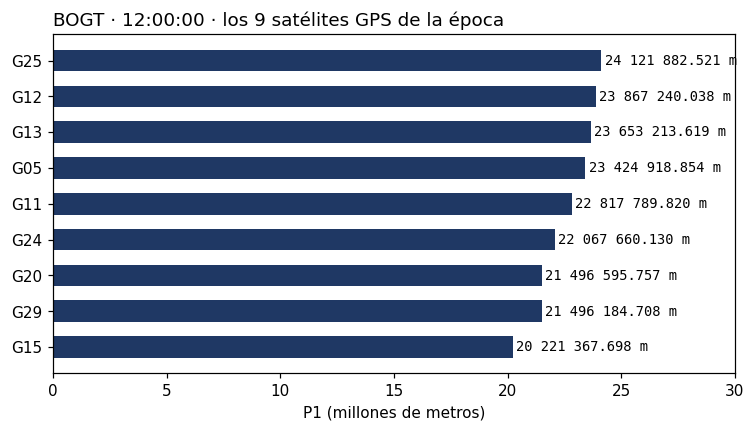

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ep.sv, ep.P1 / 1e6, color=AZUL, height=0.6)
for sv, valor in zip(ep.sv, ep.P1):
    ax.text(valor / 1e6 + 0.15, sv, f"{valor:,.3f} m".replace(",", " "), va="center", family="monospace", fontsize=9)
ax.set_xlim(0, 30)
ax.set_xlabel("P1 (millones de metros)")
ax.set_title(f"{ESTACION[:4]} · {HORA} · los {len(ep)} satélites GPS de la época", loc="left");

## 3. Un satélite a lo largo del día

Siguiendo un solo satélite (G15) durante horas, la distancia baja, pasa por un mínimo y vuelve a subir: el satélite **sale por el horizonte, culmina y se oculta**. En el mínimo está cerca de la vertical de la estación, así que ese mínimo es aproximadamente la **altura de la órbita** (unos 20 200 km). La columna `el` (elevación sobre el horizonte, en grados) confirma la lectura.

G15 visible de 08:55 a 15:09 (374 min)
distancia mínima 20,180,322 m a las 11:45:30, con elevación 72.5°


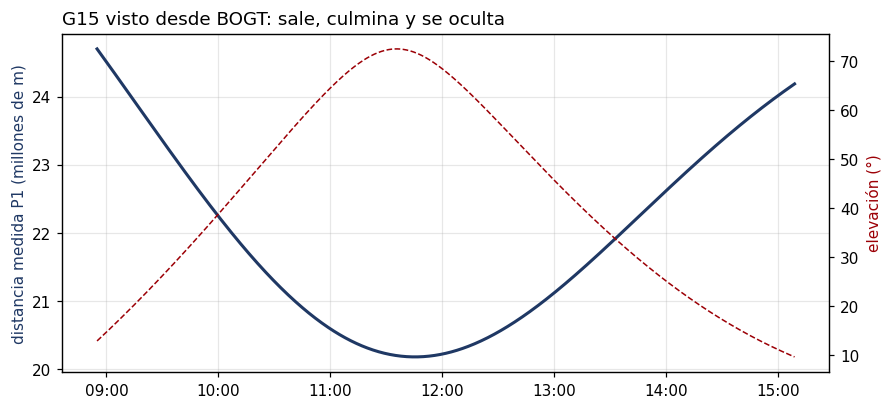

In [9]:
g15 = D[D.sv == SAT].set_index("t").sort_index()      # el satélite elegido (G15 en el ejemplo)

# un "pase" es el tramo continuo en que el satélite estuvo visible: se corta donde hay un hueco de más de 5 min
hueco = g15.index.to_series().diff() > pd.Timedelta("5min")
numero_de_pase = hueco.cumsum()
pase_de_las_12 = numero_de_pase[g15.index[g15.index.get_indexer([t0], method="nearest")[0]]]
pase = g15[numero_de_pase == pase_de_las_12]

duracion_min = (pase.index[-1] - pase.index[0]).total_seconds() / 60
print(f"{SAT} visible de {pase.index[0].strftime('%H:%M')} a {pase.index[-1].strftime('%H:%M')} ({duracion_min:.0f} min)")
print(f"distancia mínima {pase.P1.min():,.0f} m a las {pase.P1.idxmin().strftime('%H:%M:%S')}, con elevación {pase.el.max():.1f}°")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()                                   # segundo eje para la elevación
ax1.plot(pase.index, pase.P1 / 1e6, color=AZUL, lw=2)
ax2.plot(pase.index, pase.el, color=ROJO, lw=1, ls="--")
ax1.set_ylabel("distancia medida P1 (millones de m)", color=AZUL)
ax2.set_ylabel("elevación (°)", color=ROJO)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax1.set_title(f"{SAT} visto desde {ESTACION[:4]}: sale, culmina y se oculta", loc="left")
ax1.grid(alpha=0.3);

## 4. Cuántos satélites se ven a la vez

Los satélites entran y salen continuamente, pero nunca faltan. La línea de **cuatro** marca el mínimo con el que un receptor puede calcular su posición (tres coordenadas y su propio reloj, como se verá al final).

satélites GPS por época: mínimo 7, máximo 12, media 9.5


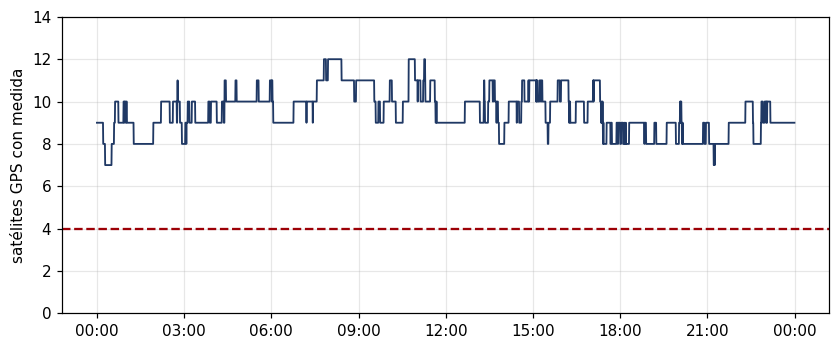

In [10]:
n_por_epoca = D.groupby("t").sv.count()             # cuántos satélites tienen medida en cada época
print(f"satélites GPS por época: mínimo {n_por_epoca.min()}, máximo {n_por_epoca.max()}, media {n_por_epoca.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(n_por_epoca.index, n_por_epoca.values, color=AZUL, lw=1.2)
ax.axhline(4, color=ROJO, ls="--")
ax.set_ylim(0, 14)
ax.set_ylabel("satélites GPS con medida")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(alpha=0.3);

## 5. La distancia se mide con un reloj

> El receptor no mide metros: mide **cuánto tarda la señal en llegar**. Si la señal sale del satélite en el instante $t^s$ y llega en $t_R$, la distancia recorrida es $d = c\,(t_R - t^s)$, con $c = 299\,792\,458$ m/s.

Esa igualdad convierte errores de tiempo en errores de distancia: 1 ns son 30 cm; 1 µs, 300 m; 1 ms, 300 km. Medir 20 000 km con precisión de metros exige medir tiempos con precisión de **nanosegundos**: por eso los satélites llevan relojes atómicos.

In [11]:
for dt, nombre in [(1e-9, "1 ns"), (1e-6, "1 µs"), (1e-3, "1 ms")]:
    print(f"{nombre:>6} de error en el tiempo -> {C*dt:>12,.2f} m de error en la distancia".replace(",", " "))

P15 = float(ep.loc[ep.sv == SAT, "P1"].iloc[0])     # la pseudodistancia del satélite elegido en la época
tau = P15 / C                                        # tiempo de viaje de la señal (s)
print(f"\n{SAT} a las {HORA}: P1 = {P15:,.3f} m  ->  tiempo de viaje = {tau*1e3:.3f} ms".replace(",", " "))

  1 ns de error en el tiempo ->         0.30 m de error en la distancia
  1 µs de error en el tiempo ->       299.79 m de error en la distancia
  1 ms de error en el tiempo ->   299 792.46 m de error en la distancia

G15 a las 12:00:00: P1 = 20 221 367.698 m  ->  tiempo de viaje = 67.451 ms


## 6. Dónde estaba el satélite: la posición que viene en el mensaje

Cada satélite transmite sus **efemérides** (los seis elementos de su órbita más pequeñas correcciones) y con ellas se calcula dónde estaba en el instante de emisión. Esa posición ya está en el archivo (`xs, ys, zs`). Su distancia al centro de la Tierra, unos 26 500 km, es el radio de la órbita: restando el radio terrestre (unos 6 371 km) queda la altura de unos 20 200 km. Las órbitas no son círculos exactos: ese radio varía unos cientos de kilómetros entre satélites y a lo largo del día.

Con geometría elemental, si la órbita fuera un círculo de radio $a$ y la estación estuviera a una distancia $R$ del centro de la Tierra: un satélite en la vertical del receptor está a $a - R$ km; uno en el horizonte, a $\sqrt{a^2 - R^2}$ km. Es aproximadamente el rango de la curva de la sección 3; como las órbitas reales son elipses, en un día se miden distancias algo fuera de ese rango.

In [12]:
ep["radio_km"] = np.sqrt(ep["xs"]**2 + ep["ys"]**2 + ep["zs"]**2) / 1e3   # distancia del satélite al centro de la Tierra
print(ep[["sv", "radio_km"]].round(1).to_string(index=False))

R_t = np.linalg.norm(rx) / 1e3    # distancia de la estación al centro de la Tierra (km)
a = 26560.0       # semieje mayor de la órbita GPS (km)
print(f"\nradio de las órbitas en esta época: de {ep.radio_km.min():,.0f} a {ep.radio_km.max():,.0f} km".replace(",", " "))
print(f"órbita circular de {a:,.0f} km; estación a {R_t:,.1f} km del centro -> en el cenit: a - R = {a-R_t:,.0f} km   |   en el horizonte: sqrt(a² - R²) = {np.sqrt(a**2-R_t**2):,.0f} km".replace(",", " "))

 sv  radio_km
G15   26394.8
G29   26467.8
G20   26598.9
G24   26724.4
G11   26513.3
G05   26418.7
G13   26612.9
G12   26767.7
G25   26853.6

radio de las órbitas en esta época: de 26 395 a 26 854 km
órbita circular de 26 560 km; estación a 6 380.6 km del centro -> en el cenit: a - R = 20 179 km   |   en el horizonte: sqrt(a² - R²) = 25 782 km


## 7. Distancia medida y distancia geométrica: los relojes de los satélites

> **Distancia geométrica** $r$ — la distancia real entre el satélite (en el instante de emisión) y el receptor: $r = \sqrt{(x - x^s)^2 + (y - y^s)^2 + (z - z^s)^2}$.

Como la posición de la estación se conoce (la del encabezado), se puede calcular $r$ y compararla con la medida. **No coinciden**: difieren en ±100 km, un valor distinto para cada satélite. Son los **relojes de los satélites**: cada uno marca la hora de emisión con un adelanto o atraso propio de cientos de microsegundos (a 300 km por milisegundo). El satélite conoce su desviación —el segmento de control la mide y la sube al mensaje— y la transmite: es la columna `dts`.

In [13]:
# distancia geométrica: del satélite (en el instante de emisión) a la posición de la estación
ep["r"] = np.sqrt((rx[0] - ep["xs"])**2 + (rx[1] - ep["ys"])**2 + (rx[2] - ep["zs"])**2)

ep["P_menos_r"] = ep.P1 - ep.r          # medida − geométrica: debería ser ~0 si los relojes fueran perfectos
ep["c_dts"] = C * ep.dts                # error del reloj del satélite, pasado a metros
ep["resid"] = ep.P1 - ep.r + ep.c_dts   # lo que queda tras corregir el reloj del satélite

ep[["sv", "el", "P1", "r", "P_menos_r", "c_dts", "resid"]].round(3)

,sv,el,P1,r,P_menos_r,c_dts,resid
0,G15,68.513,2.022137e+07,2.035474e+07,-133369.109,133372.634,3.525
1,G29,47.305,2.149618e+07,2.142342e+07,72767.193,-72763.214,3.979
2,G20,46.896,2.149660e+07,2.158236e+07,-85759.609,85762.858,3.248
3,G24,40.558,2.206766e+07,2.213019e+07,-62533.631,62539.257,5.626
4,G11,29.830,2.281779e+07,2.275506e+07,62725.881,-62718.618,7.263
5,G05,22.068,2.342492e+07,2.335393e+07,70992.733,-70984.934,7.799
6,G13,19.560,2.365321e+07,2.378586e+07,-132642.357,132652.265,9.908
7,G12,22.278,2.386724e+07,2.368675e+07,180494.861,-180485.335,9.525
8,G25,17.461,2.412188e+07,2.423832e+07,-116435.256,116446.638,11.382


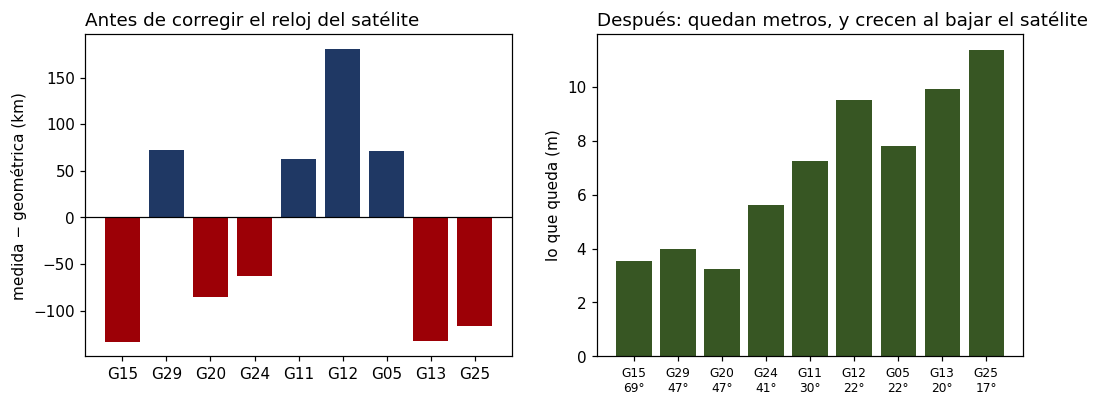

In [14]:
e2 = ep.sort_values("el", ascending=False)    # de más alto a más bajo sobre el horizonte
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))

colores = [ROJO if v < 0 else AZUL for v in e2.P_menos_r]
axs[0].bar(e2.sv, e2.P_menos_r / 1e3, color=colores)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_ylabel("medida − geométrica (km)")
axs[0].set_title("Antes de corregir el reloj del satélite", loc="left")

axs[1].bar(e2.sv, e2.resid, color=VERDE)
axs[1].set_ylabel("lo que queda (m)")
axs[1].set_title("Después: quedan metros, y crecen al bajar el satélite", loc="left")
axs[1].set_xticks(range(len(e2)))
axs[1].set_xticklabels([f"{s}\n{e:.0f}°" for s, e in zip(e2.sv, e2.el)], fontsize=8);

## 8. Lo que queda depende de la elevación: la atmósfera

Tras corregir el reloj del satélite quedan unos metros, y son mayores para los satélites bajos. Siguiendo a G15 durante todo su pase se ve la forma: la señal de un satélite bajo atraviesa más atmósfera y llega más tarde. Además queda una parte común a todos los satélites de la época: el error del **reloj del receptor**, que se calculará como incógnita.

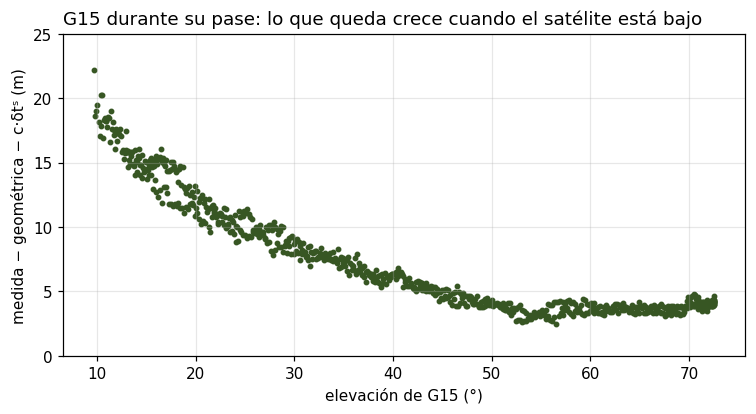

In [15]:
pase = pase.copy()
pase["r"] = np.sqrt((rx[0] - pase["xs"])**2 + (rx[1] - pase["ys"])**2 + (rx[2] - pase["zs"])**2)
pase["resid"] = pase.P1 - pase.r + C * pase.dts      # medida − geométrica − (−c·δtˢ)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(pase.el, pase.resid, s=8, color=VERDE)
ax.set_xlabel(f"elevación de {SAT} (°)")
ax.set_ylabel("medida − geométrica + c·δtˢ (m)")
ax.set_ylim(0, 25)
ax.grid(alpha=0.3)
ax.set_title(f"{SAT} durante su pase: lo que queda crece cuando el satélite está bajo", loc="left");

## 9. La misma distancia en dos frecuencias: la huella de la ionosfera

El mismo satélite se mide a la vez en L1 (`P1`) y L2 (`P2`). Si el retraso de la señal no dependiera de la frecuencia, las dos distancias serían iguales. No lo son: la diferencia crece cuando el satélite está bajo y cuando el sol ya ha ionizado la atmósfera (el pase de G15 va de las 03:55 a las 10:09 hora de Colombia). Es la firma de la **ionosfera**, que retrasa más a la frecuencia más baja (L2). El desfase casi constante de la madrugada (unos −1,5 m) es instrumental: los circuitos de L1 y L2 no retrasan igual la señal.

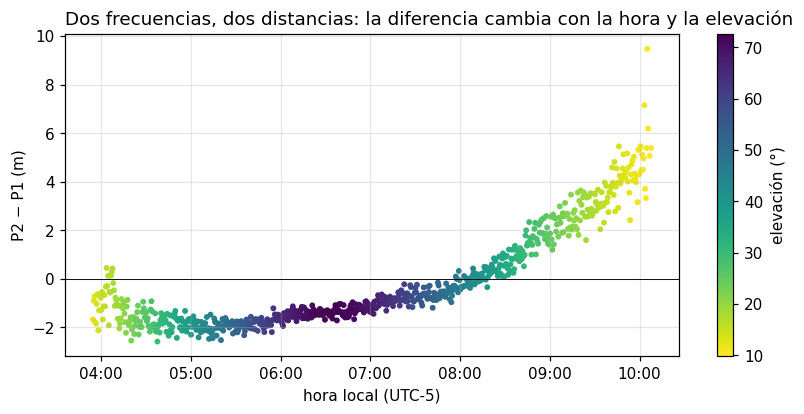

In [16]:
# tiempo GPS -> UTC (restar los 18 s intercalares) -> hora local (UTC + HUSO; Colombia: −5)
hora_local = pase.index + pd.Timedelta(hours=HUSO) - pd.Timedelta(seconds=18)

fig, ax = plt.subplots(figsize=(9, 3.8))
sc = ax.scatter(hora_local, pase.P2 - pase.P1, s=8, c=pase.el, cmap="viridis_r")
fig.colorbar(sc, ax=ax, label="elevación (°)")
ax.axhline(0, color="k", lw=0.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel(f"hora local (UTC{HUSO:+d})")
ax.set_ylabel("P2 − P1 (m)")
ax.set_title("Dos frecuencias, dos distancias: la diferencia cambia con la hora y la elevación", loc="left")
ax.grid(alpha=0.3);

## 10. La ecuación de la pseudodistancia

> **Pseudodistancia (*pseudorange*), $\rho$** — la distancia que mide el código: la geométrica más el efecto de los dos relojes, de la atmósfera y del ruido.
> $$\rho = r + c\,(\delta t_R - \delta t^s) + T + I + \varepsilon$$
> $r$: distancia geométrica · $c$: velocidad de la luz · $\delta t_R$: error del reloj del receptor (desconocido) · $\delta t^s$: error del reloj del satélite (transmitido) · $T$: retraso troposférico (sección 8) · $I$: retraso ionosférico (sección 9) · $\varepsilon$: reflexiones (multitrayectoria) y ruido.

Cada término es mucho menor que el anterior: la distancia, unos 20 000 km; el reloj del satélite, cientos de kilómetros; la atmósfera, de 3 a 20 m; el ruido, decímetros. Los dos relojes entran con signo opuesto: si el reloj del receptor adelanta, la señal parece llegar más tarde y $\rho$ crece; si adelanta el del satélite, parece salir más tarde y $\rho$ disminuye.

Con los números de G15 a las 12:00:00, todo cuadra: el reloj del satélite explica 133 km de diferencia y lo que queda son unos metros, casi todos de atmósfera.

In [17]:
g = ep[ep.sv == SAT].iloc[0]
print(f"ρ        = {g.P1:,.3f} m".replace(",", " "))
print(f"r        = {g.r:,.3f} m".replace(",", " "))
print(f"c·δtˢ    = {C*g.dts:,.1f} m   (δtˢ = {g.dts*1e6:.3f} µs)".replace(",", " "))
print(f"ρ − r + c·δtˢ = {g.P1 - g.r + C*g.dts:,.2f} m  = c·δt_R + T + I + ε".replace(",", " "))

ρ        = 20 221 367.698 m
r        = 20 354 736.807 m
c·δtˢ    = 133 372.6 m   (δtˢ = 444.883 µs)
ρ − r + c·δtˢ = 3.53 m  = c·δt_R + T + I + ε


## 11. Por qué hacen falta cuatro satélites

Para cada satélite $i$ de una época:
$$\rho_i + c\,\delta t^i - T_i - I_i = \sqrt{(x - x^i)^2 + (y - y^i)^2 + (z - z^i)^2} + c\,\delta t_R + \varepsilon_i$$
Lo conocido: $\rho_i$ (medido), $x^i, y^i, z^i, \delta t^i$ (del mensaje), $T_i$ (de un modelo de la troposfera) e $I_i$ (medido con dos frecuencias o, en un receptor de una sola frecuencia, de un modelo del mensaje). Lo desconocido, y común a todas las ecuaciones: $x, y, z$ y $\delta t_R$. **Cuatro incógnitas** → hacen falta al menos cuatro satélites. BOGT tuvo nueve a las 12:00 y nunca menos de siete en el día. Resolver ese sistema es el tema del cuaderno `gnss_estimacion_posicion.ipynb`.

## Referencias

- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg): señal, mensaje de navegación, cálculo de la posición y el reloj del satélite.
- ESA Navipedia (gssc.esa.int/navipedia): GPS Space Segment, GPS Signal Plan, GPS Navigation Message.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*.
- IGS, International GNSS Service (igs.org); datos de BOGT del centro de datos IGS en BKG: https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ . RINEX 3.04 (IGS/RTCM RINEX Working Group, 2018).
- Paquete `hatanaka` (descompresión de los archivos `.crx`): https://pypi.org/project/hatanaka/